In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from hcipy import *
from psfGenerator import PsfGenerator
sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from adcFitter_onsky import AdcFitter

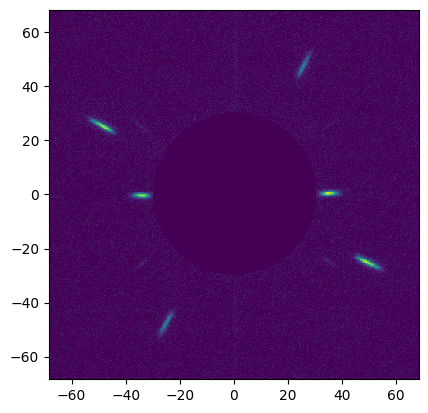

In [5]:
fieldcube = read_field('/Users/Katie/Documents/Fall 2023/MagAO-X/ADC Sim code/updated onsky/all_lab_fields_i.fits')
img = fieldcube[0]
imshow_field(img)

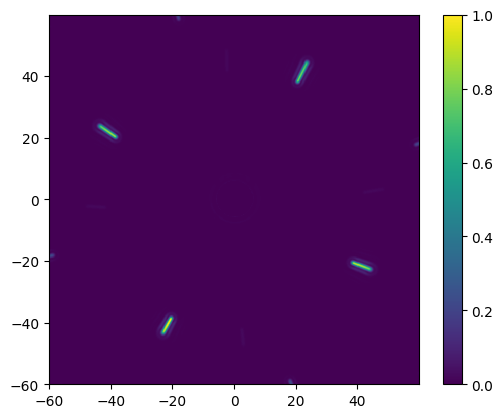

In [64]:
wavelength = 764E-9
bw = 120E-9
wavelength_normalized = wavelength / 656E-9
bw_normalized = bw / wavelength
grating_angle = 28
grating_freq = 40

ADC = AdcFitter(wavelength=wavelength,bandwidth=bw,grating_angle=grating_angle,grating_freq=grating_freq)

PsfGen = PsfGenerator(center_wavelength=wavelength_normalized,bandwidth=bw_normalized, focal_sampling=6, focal_extent=60,grating_angle=grating_angle, fx=grating_freq, fy = grating_freq, mask=True)
disp_x = np.random.rand() * 0.05
disp_y = np.random.rand() * 0.05

psf = PsfGen.psf(magnitude_x=disp_x,magnitude_y=disp_y)
ADC.set_psf(psf)

imshow_field(ADC.psf)
plt.colorbar()

In [ ]:
#let's look at the fit visually
def visualize_fit(image):
    speckle_angles = np.zeros(4)
    sig_x = [1,3.5,1,3.5]
    sig_y = [3.5,1,3.5,1]
    fit_image = image - image

    for i in range(4):
        img = ADC.find_speckle(ADC.psf,i)
        ADC.current_speckle = i
        ADC.set_measurement(img)

        sigma_x = .5#sig_x[i]
        sigma_y = .5#sig_y[i]
        orientation = np.radians(30)

        # orientation = ADC.estimate_angle()
        # if ADC.current_speckle == 0 or ADC.current_speckle ==2:
        #     orientation = np.pi/2 - orientation
        # elif ADC.current_speckle == 1 or ADC.current_speckle == 3:
        #     orientation = -orientation

        amplitude = ADC.data.max()
        centroid = ADC.estimate_centroid()
        mu_x = centroid[0]
        mu_y = centroid[1]
        background = 0

        theta_est = np.array([amplitude, mu_x, mu_y, sigma_x, sigma_y, orientation, background])
        fit = ADC.fit(theta_est) 
        theta = fit.x
        speckle_angles[i] = np.degrees(theta[5])
        fit_image = fit_image + ADC.satellite_spot(*theta)(image.grid)
        print(f'initial orientation value {orientation} fitted value {theta[5]}')
        #print(f'aspect ratio:{np.abs(theta[3]/theta[4])}')

    ADC.current_speckle = None
    speckle_angles = np.array(speckle_angles).T

    print(f'aspect ratio:{np.abs(theta[3]/theta[4])}')
    print(f'speckle angles:{speckle_angles}')
    return fit_image

initial orientation value 0 fitted value 0.6428467636123423
initial orientation value 0 fitted value 0.5495409321721745
initial orientation value 0 fitted value 0.5122934008148123
initial orientation value 0 fitted value 0.8072011774819082
aspect ratio:1.8988297818910758
speckle angles:[36.83240643 31.48637608 29.35224974 46.24922069]


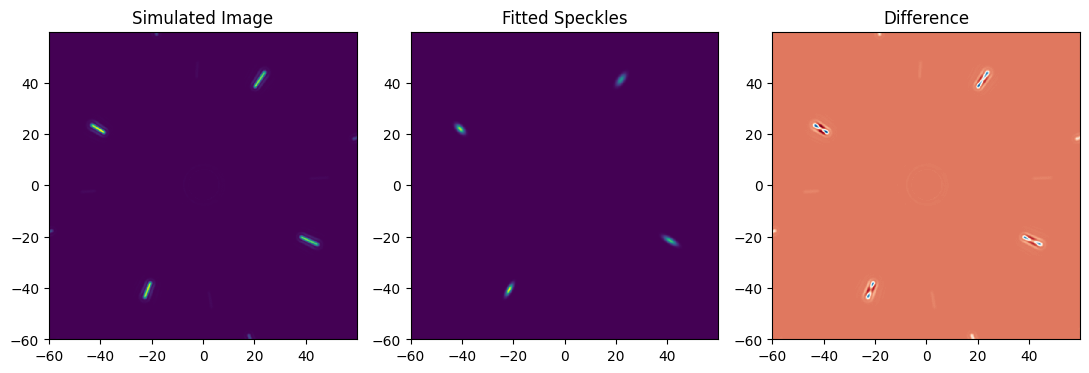

In [65]:
psf = PsfGen.noisy_turbulent_psf(magnitude_x=0.05,magnitude_y=0,num_photons=1E8,ptv=0,diam=1)
ADC.set_psf(psf)

fitted = visualize_fit(ADC.psf)

plt.figure(figsize=(11,5))
plt.subplot(1,3,1)
imshow_field(ADC.psf)
plt.title('Simulated Image')
plt.subplot(1,3,2)
imshow_field(fitted)
plt.title('Fitted Speckles')
plt.subplot(1,3,3)
imshow_field(ADC.psf - fitted,cmap='RdBu')
plt.title('Difference')
plt.tight_layout()
plt.show()

aspect ratio:0.2527858693908127
aspect ratio:2.992539013564996
aspect ratio:0.21489624234888932
aspect ratio:4.023373677117475
aspect ratio:4.023373677117475
speckle angles:[33.65978182 18.65728232 22.61472376 33.36914533]


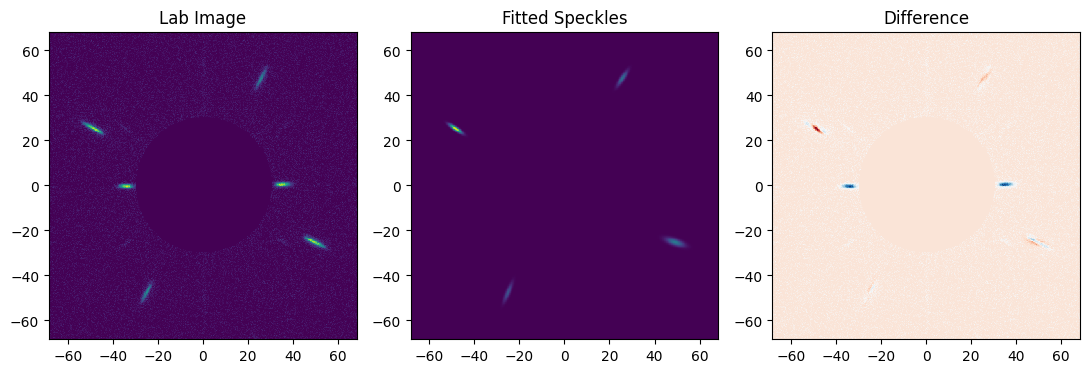

In [6]:
#same thing,but with a real lab image
ADC.set_psf(img)
real_fitted = visualize_fit(img)

plt.figure(figsize=(11,5))
plt.subplot(1,3,1)
imshow_field(img)
plt.title('Lab Image')
plt.subplot(1,3,2)
imshow_field(real_fitted)
plt.title('Fitted Speckles')
plt.subplot(1,3,3)
imshow_field(img - real_fitted,cmap='RdBu')
plt.title('Difference')
plt.tight_layout()
plt.show()

In [14]:
#now let's see if there's bias in the simulated images if we use zero dispersion and introduce some poisson noise:
pairs = []
num_photons = 1E6

for i in range(20):
    psf = PsfGen.noisy_turbulent_psf(magnitude_x=0,magnitude_y=0,num_photons=num_photons,ptv=0.3)
    ADC.set_psf(psf)

    angles = ADC.find_speckle_angles()
    pair = ADC.speckle_pairs(angles)
    pairs.append(pair)

    if np.any(np.abs(pair) > 10):
        break

pairs = np.matrix(pairs)

3.5442218846142435
2.993742229902919
3.3624566770930504
3.098625798620488
3.1348488993954695
3.3220257511001705
3.263450386628143
3.2834483907223904
2.856368525597675
3.488907685360517
3.6996790344921116
3.4275504523422864
3.4683975984250592
3.220436927060169
2.9976797525205376
3.2719259085054877
3.733851146933205
3.38142092894841
3.189888893669072
3.649736392545316


In [15]:
print(angles)
print(f'mean offset: {np.mean(pairs,axis=0)}°')
print(f'sd of pointing offsets: {np.std(pairs,axis=0)}°')

[28.82679519 28.7897356  27.78644543 27.80912829]
mean offset: [[ 0.14743068 -0.36826764]]°
sd of pointing offsets: [[1.63557674 1.70661045]]°


mean offset: [[ 0.44470891 -0.33722558]]°
sd of pointing offsets: [[0.7873589  1.36843292]]°


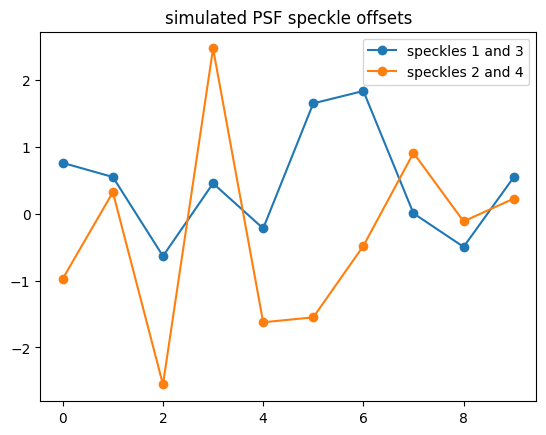

In [12]:
print(f'mean offset: {np.mean(pairs,axis=0)}°')
print(f'sd of pointing offsets: {np.std(pairs,axis=0)}°')

plt.plot(pairs[0:80,0],'o-',label='speckles 1 and 3')
plt.plot(pairs[:,1],'o-',label='speckles 2 and 4')
plt.title('simulated PSF speckle offsets')
plt.legend()
plt.show()